# SmartCoach Ciclismo Colombia — Exploratory Data Analysis and Modeling (CRISP-DM)
**Author:** Fabian Melendez (Member 1 · Machine Learning & Data Engineer)

This notebook documents CRISP-DM phases 2 to 5 required by the project proposal: data sources, data quality, preparation, model comparison and limitations.

| Phase | Section |
|---|---|
| 2. Data understanding | 1 (datos.gov.co) and 2 (Kaggle) |
| 3. Data preparation | 3 |
| 4. Modeling | 4 |
| 5. Evaluation | 5 and 6 |

**How to run it:** use *Run All*. If VS Code asks for a kernel, choose your Python 3.12.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (8, 4)

BASE = os.path.abspath(os.path.join(os.getcwd(), ".."))      # ml_engine folder
DATA = os.path.join(BASE, "data")
ART  = os.path.join(BASE, "model_artifacts")
sys.path.insert(0, BASE)
import train_model as tm            # reuses FEATURE_NAMES, TARGET, CLASSES and the candidate models
print("ml_engine:", BASE)

ml_engine: c:\Users\USUARIO\Desktop\hola\Fabian\semestre6\Machine\proyecto final\SMARTCOACH\smartcoach_ciclismo\ml_engine


## 1. Source A — datos.gov.co: *Atletas y ParaAtletas apoyados* (supported athletes)
**What it is:** an institutional registry of supported athletes (2021–2022). **Key question from the proposal:** does it include cyclists, training metrics or variables suitable for training? We check it.

In [2]:
raw = pd.read_csv(os.path.join(DATA, "datos_gov_ciclismo_raw.csv"))
print("Rows, columns:", raw.shape)
display(raw.head())
display(raw.dtypes.to_frame("dtype"))
print("Missing values per column:\n", raw.isna().sum().to_string())
print("\nDuplicated rows:", raw.duplicated().sum(), "| distinct IDs:", raw["ID"].nunique())

Rows, columns: (60000, 11)


,ID,Tipo_Atleta,sexo,Deporte,Rango_Edad,Organización_deportiva,Subregión_nacimiento,Municipio_nacimiento,Año,Mes,Permanencia
0,"129,719",Atletas convencionales,Hombre,Esquí Nautico,2014-10-01T00:00:00.000,Esqui Nautico,Valle de Aburrá,Medellín,"2,021",1,Activo
1,"129,719",Atletas convencionales,Hombre,Esquí Nautico,2014-10-01T00:00:00.000,Esqui Nautico,Valle de Aburrá,Medellín,"2,021",10,Activo
2,"129,719",Atletas convencionales,Hombre,Esquí Nautico,2014-10-01T00:00:00.000,Esqui Nautico,Valle de Aburrá,Medellín,"2,021",11,Activo
3,"129,719",Atletas convencionales,Hombre,Esquí Nautico,2014-10-01T00:00:00.000,Esqui Nautico,Valle de Aburrá,Medellín,"2,021",12,Activo
4,"129,719",Atletas convencionales,Hombre,Esquí Nautico,2014-10-01T00:00:00.000,Esqui Nautico,Valle de Aburrá,Medellín,"2,021",2,Activo


,dtype
ID,str
Tipo_Atleta,str
sexo,str
Deporte,str
Rango_Edad,str
Organización_deportiva,str
Subregión_nacimiento,str
Municipio_nacimiento,str
Año,str
Mes,int64


Missing values per column:
 ID                        0
Tipo_Atleta               0
sexo                      0
Deporte                   0
Rango_Edad                0
Organización_deportiva    0
Subregión_nacimiento      0
Municipio_nacimiento      0
Año                       0
Mes                       0
Permanencia               0

Duplicated rows: 0 | distinct IDs: 2440


**Data quality problems found**
- `ID` and `Año` are stored as text with a thousands separator (`"129,719"`, `"2,021"`).
- `Rango_Edad` (age range) is corrupted: the range **10-14** was wrongly converted into a date (Excel), and appears as `41913` or `2014-10-01T00:00:00.000`.
- Each row is a **monthly** record of an athlete (60,000 rows for about 2,400 athletes), not one row per athlete.

In [3]:
print(raw["Rango_Edad"].value_counts().to_string())

Rango_Edad
20-24                      20973
15-19                      14165
25-29                      11926
30-34                       6160
35-39                       2832
40-44                       1515
41913                        713
45-49                        650
50-54                        551
55-59                        257
60-64                        127
65-69                         95
70-74                         24
2014-10-01T00:00:00.000       12


In [4]:
df_gov = raw.copy()
df_gov["ID"]  = df_gov["ID"].astype(str).str.replace(",", "", regex=False).astype(int)
df_gov["Año"] = df_gov["Año"].astype(str).str.replace(",", "", regex=False).astype(int)
df_gov["Rango_Edad"] = df_gov["Rango_Edad"].astype(str).replace(
    {"41913": "10-14", "2014-10-01T00:00:00.000": "10-14"})
print(df_gov["Rango_Edad"].value_counts().sort_index().to_string())

Rango_Edad
10-14      725
15-19    14165
20-24    20973
25-29    11926
30-34     6160
35-39     2832
40-44     1515
45-49      650
50-54      551
55-59      257
60-64      127
65-69       95
70-74       24


Cycling records: 2150 | distinct cyclists: 67


,records
Deporte,
Ciclismo Pista,1162
Ciclismo BMX,506
Ciclismo Ruta,482


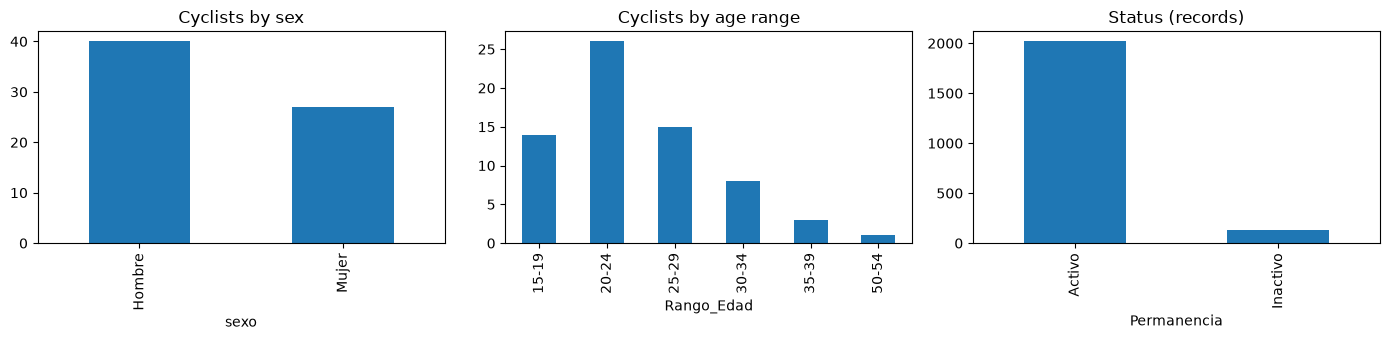

In [5]:
cic = df_gov[df_gov["Deporte"].str.contains("Ciclismo", case=False, na=False)].copy()   # "Ciclismo" = cycling
print("Cycling records:", len(cic), "| distinct cyclists:", cic["ID"].nunique())
display(cic["Deporte"].value_counts().to_frame("records"))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
cic.drop_duplicates("ID")["sexo"].value_counts().plot.bar(ax=ax[0], title="Cyclists by sex")
cic.drop_duplicates("ID")["Rango_Edad"].value_counts().sort_index().plot.bar(ax=ax[1], title="Cyclists by age range")
cic["Permanencia"].value_counts().plot.bar(ax=ax[2], title="Status (records)")
plt.tight_layout(); plt.show()

In [6]:
out = os.path.join(DATA, "datos_gov_ciclismo.csv")
cic.to_csv(out, index=False, encoding="utf-8")
print("Saved:", out)

Saved: c:\Users\USUARIO\Desktop\hola\Fabian\semestre6\Machine\proyecto final\SMARTCOACH\smartcoach_ciclismo\ml_engine\data\datos_gov_ciclismo.csv


**Conclusion for Source A.** It contains Colombian cyclists (track, BMX and road) but **only demographic variables**: there is no load, RPE, fatigue or injury data. Therefore:
- It is **not used to train the model** nor as a label (as the proposal warns).
- It is used to **give context** about the target population and as **initial seed data** (`seed_service.py`, owned by Paula) through the file `datos_gov_ciclismo.csv`.

## 2. Source B — Kaggle: *Multimodal Sports Injury Dataset* (Bhegam)
Documentation sheet (fill in the download date before submitting):

| Field | Value |
|---|---|
| URL | https://www.kaggle.com/datasets/anjalibhegam/multimodal-sports-injury-dataset |
| Version | 1.0 |
| Download date | *(fill in)* |
| License | CC BY-NC-SA 4.0 (non-commercial use, with attribution) |
| Local file | `ml_engine/data/sports_injury_data.csv` |

In [7]:
kg = pd.read_csv(os.path.join(DATA, "sports_injury_data.csv"))
print("Rows, columns:", kg.shape, "| athletes:", kg["athlete_id"].nunique())
display(kg.head())
nulls = (kg.isna().mean() * 100).round(2)
print("Columns with missing values (%):\n", nulls[nulls > 0].to_string())
print("\nDuplicates:", kg.duplicated().sum())

Rows, columns: (15420, 29) | athletes: 156


,athlete_id,heart_rate,body_temperature,hydration_level,sleep_quality,recovery_score,stress_level,muscle_activity,joint_angles,gait_speed,cadence,step_count,jump_height,ground_reaction_force,range_of_motion,ambient_temperature,humidity,altitude,playing_surface,training_intensity,training_duration,training_load,fatigue_index,injury_occurred,session_id,sport_type,gender,age,bmi
0,1,NaN,37.048668,76.481477,5.466370,77.899691,0.375825,10.000000,126.480118,2.654327,50.000000,4961,0.453083,1859.705455,113.448072,17.603241,47.315106,34.853588,0,5.678475,79.106564,548.417962,45.028687,0,1,Basketball,Female,18,25.105748
1,1,40.000000,36.929536,72.363938,6.899090,74.845323,0.279165,310.293156,157.631630,3.431107,89.032626,9006,0.265763,1852.051883,146.174914,25.107144,72.397626,241.114332,1,NaN,116.954654,538.043815,42.254717,2,2,Basketball,Female,18,25.105748
2,1,76.174609,36.334841,100.000000,9.574152,83.538316,0.334061,158.659094,81.766287,0.800000,73.088441,6775,0.850000,1654.115836,120.710518,27.894979,64.385922,236.488382,1,6.643242,96.354742,647.784339,61.870056,0,3,Basketball,Female,18,25.105748
3,1,100.543724,37.244474,86.172473,7.614297,79.966618,0.218766,107.079298,113.023701,1.713869,50.000000,6579,0.489573,1727.371018,142.688855,27.886378,46.832571,290.514087,0,6.194427,97.619130,336.553431,50.268845,0,4,Basketball,Female,18,25.105748
4,1,78.001235,36.510766,83.195889,5.631979,56.945979,0.484086,164.347133,112.814695,2.154233,71.288255,8157,0.466310,1642.459351,127.456337,22.812019,70.206802,424.735161,0,5.835804,83.155527,496.076352,29.233575,2,5,Basketball,Female,18,25.105748


Columns with missing values (%):
 heart_rate            2.3
hydration_level       2.5
sleep_quality         3.2
muscle_activity       3.7
gait_speed            2.8
training_intensity    4.1

Duplicates: 0


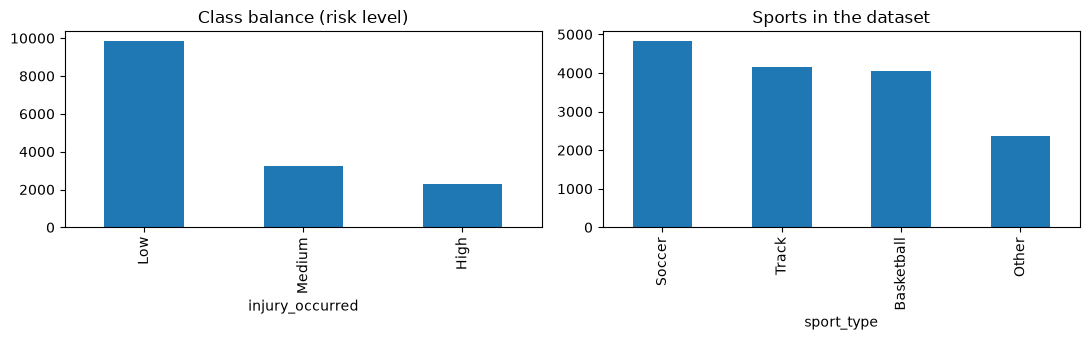

injury_occurred
Low       64.0
Medium    21.0
High      15.0


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
cnt = kg[tm.TARGET].map(tm.CLASSES).value_counts()
cnt.plot.bar(ax=ax[0], title="Class balance (risk level)")
kg["sport_type"].value_counts().plot.bar(ax=ax[1], title="Sports in the dataset")
plt.tight_layout(); plt.show()
print((cnt / cnt.sum() * 100).round(1).to_string())

**Relevance.** The dataset covers soccer, basketball, track and other sports: **it is not about cyclists**. Its results cannot be assumed to represent Colombian cyclists; this must be stated in the limitations of the report. In addition, the classes are imbalanced (~64 / 21 / 15 %), so overall accuracy is misleading.

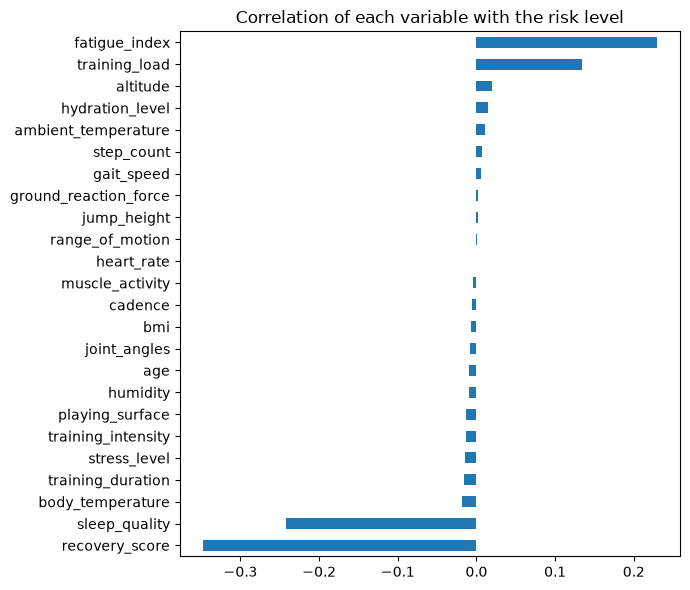

In [9]:
corr = kg.drop(columns=["sport_type", "gender"]).corr()[tm.TARGET].drop([tm.TARGET, "athlete_id", "session_id"])
corr.sort_values().plot.barh(figsize=(7, 6), title="Correlation of each variable with the risk level")
plt.tight_layout(); plt.show()

The variables most related to risk are **recovery_score**, **sleep_quality**, **fatigue_index** and **training_load**. This is why the app needs a *daily check-in* for sleep, recovery and fatigue: without them the model loses almost all of its signal.

In [10]:
ratio = (kg["training_intensity"] * kg["training_duration"] / kg["training_load"]).describe()
print("RPE x duration / training_load  ->  median:", round(ratio["50%"], 2))

RPE x duration / training_load  ->  median: 0.89


That ratio is around 0.9, which means `training_load ≈ RPE × duration` (the sRPE method). This is the formula the app must use to compute each session's load; dividing by 10 as in the initial guide would feed the model values about 10 times lower than those it learned from.

## 3. Data preparation
Decisions taken (and reproduced in `train_model.py`):

1. **Features (9):** age, bmi, intensity (RPE), duration, load, mean heart rate, sleep, recovery, fatigue. They were chosen because the app can record or compute them; the biomechanical and environmental sensors were discarded (not available in a cycling training log).
2. **Missing values (~3 %):** imputed with the **median** of each variable.
3. **Split by athlete** (`GroupShuffleSplit`): no athlete appears in both training and test. Each athlete has ~99 sessions with constant age and bmi, so a random split could let the model "recognize" the athlete. It is the safest practice and the one the proposal requires (avoiding data leakage); section 5 checks its real effect on this dataset.
4. **Scaling** with `StandardScaler`, fitted on the training set only.
5. **Class imbalance:** class weights (`class_weight="balanced"` / `sample_weight`).

In [11]:
print("Model features, in order:")
for i, (k, v) in enumerate(tm.FEATURES.items(), 1):
    print(f"{i}. {k:20s} <- {v}")

Model features, in order:
1. age                  <- cyclist age (profile)
2. bmi                  <- weight(kg) / height(m)^2 (profile)
3. training_intensity   <- session rpe (1-10)
4. training_duration    <- session duracion_min
5. training_load        <- session load = rpe * duracion_min (sRPE)
6. heart_rate           <- session frecuencia_cardiaca_media
7. sleep_quality        <- daily check-in: sleep quality (2-10)
8. recovery_score       <- daily check-in: perceived recovery (25-98)
9. fatigue_index        <- daily check-in: fatigue (15-85)


## 4. Modeling — algorithm comparison

In [12]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import f1_score, accuracy_score

X = kg[tm.FEATURE_NAMES].copy()
X = X.fillna(X.median())
y = kg[tm.TARGET].astype(int)
g = kg["athlete_id"]

tr, te = next(GroupShuffleSplit(test_size=0.2, random_state=tm.RANDOM_STATE).split(X, y, g))
sc = StandardScaler()
Xtr, Xte = sc.fit_transform(X.iloc[tr]), sc.transform(X.iloc[te])
ytr, yte = y.iloc[tr], y.iloc[te]
w = ytr.map(len(ytr) / (3 * ytr.value_counts())).values

rows = []
base = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr).predict(Xte)
rows.append(("Baseline (always 'Low')", f1_score(yte, base, average="macro"), accuracy_score(yte, base), np.nan))

models = {}
for name, m in tm.build_candidates().items():
    params = {"sample_weight": w} if name == "XGBoost" else {}
    cv = cross_val_predict(m, Xtr, ytr, groups=g.iloc[tr], cv=GroupKFold(5), params=params)
    cv_f1 = f1_score(ytr, cv, average="macro")
    if name == "XGBoost": m.fit(Xtr, ytr, sample_weight=w)
    else: m.fit(Xtr, ytr)
    p = m.predict(Xte)
    models[name] = (m, p)
    rows.append((name, f1_score(yte, p, average="macro"), accuracy_score(yte, p), cv_f1))

res = pd.DataFrame(rows, columns=["model", "macro F1 (test)", "accuracy (test)", "macro F1 (CV)"]).round(3)
display(res)

,model,macro F1 (test),accuracy (test),macro F1 (CV)
0,Baseline (always 'Low'),0.262,0.648,NaN
1,RandomForest,0.421,0.447,0.440
2,XGBoost,0.421,0.430,0.435


The model with the highest **macro F1 in cross-validation** is selected (not accuracy, which favors the majority class). The baseline shows the minimum that has to be beaten.

## 5. Evaluation of the selected model

Selected model: RandomForest 

              precision    recall  f1-score   support

         Low       0.71      0.41      0.52      2055
      Medium       0.21      0.30      0.24       644
        High       0.36      0.82      0.50       472

    accuracy                           0.45      3171
   macro avg       0.43      0.51      0.42      3171
weighted avg       0.56      0.45      0.46      3171



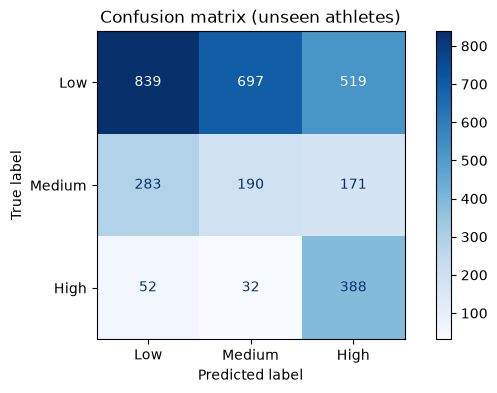

In [13]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
best = res.iloc[1:].sort_values("macro F1 (CV)", ascending=False).iloc[0]
best_name = best["model"]
m, p = models[best_name]
print("Selected model:", best_name, "\n")
print(classification_report(yte, p, target_names=list(tm.CLASSES.values())))
ConfusionMatrixDisplay.from_predictions(yte, p, display_labels=list(tm.CLASSES.values()), cmap="Blues")
plt.title("Confusion matrix (unseen athletes)"); plt.show()

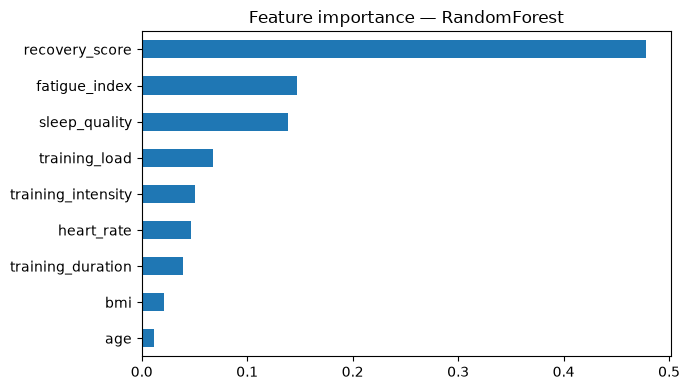

In [14]:
imp = pd.Series(m.feature_importances_, index=tm.FEATURE_NAMES).sort_values()
imp.plot.barh(title=f"Feature importance — {best_name}", figsize=(7, 4))
plt.tight_layout(); plt.show()

### Effect of not splitting by athlete (data leakage check)
Comparison between a random split and a split by athlete. In this dataset the difference is small (the signal of the variables is weak and there is no clear per-athlete fingerprint), so **no metric inflation is observed**; the split by athlete is kept anyway because it rules out that risk by design and matches the real use case (a new cyclist the model has never seen).

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
a, b, ya, yb = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1).fit(a, ya)
print("Macro F1 with RANDOM split   :", round(f1_score(yb, rf.predict(b), average="macro"), 3))
print("Macro F1 with ATHLETE split  :", round(best["macro F1 (test)"], 3))

Macro F1 with RANDOM split   : 0.474
Macro F1 with ATHLETE split  : 0.421


## 6. Exported artifacts and limitations

In [16]:
with open(os.path.join(ART, "features.json"), encoding="utf-8") as f: contract = json.load(f)
with open(os.path.join(ART, "metrics.json"), encoding="utf-8") as f: metrics = json.load(f)
print("Saved model:", contract["model_type"], "| sklearn", contract["sklearn_version"])
print("Features (order):", contract["features"])
print("Classes:", contract["classes"])
print("Test macro F1 (train_model.py):", metrics["test_macro_f1"])

Saved model: RandomForest | sklearn 1.8.0
Features (order): ['age', 'bmi', 'training_intensity', 'training_duration', 'training_load', 'heart_rate', 'sleep_quality', 'recovery_score', 'fatigue_index']
Classes: {'0': 'Low', '1': 'Medium', '2': 'High'}
Test macro F1 (train_model.py): 0.4211


### Limitations to include in the report
- The dataset is **not about cyclists**, nor Colombian ones; generalization to them has not been demonstrated (as Leckey et al., 2025, warn).
- The predictive signal is **weak** (macro F1 around 0.45): the model detects **High** risk well but confuses **Low** and **Medium**. It is presented as an **orientative alert**, not as a diagnosis.
- The **session-type recommendation** (rest, recovery, endurance, intervals) **does not come from the model**: it is built with configurable rules from the risk level and the last 7 days of load (`workload_service.py`).
- The dataset label is injury/risk, not "adequate session"; the target was therefore redefined, as phase 4 of the proposal anticipates.
- There is no cycling data with elevation gain and power; if the team collects real data, the model must be retrained and externally validated.